# SPI and Copula Analysis

**Aim.** Compute the Standardized Precipitation Index (SPI) for one Sri Lankan district step by step, turn it into
drought events, and describe how long and how severe those droughts are, and how often they return, with a
duration-severity copula. The last section repeats the headline results for all 25 districts.

Every number comes from the project's own modules (`spi_copula_analysis.py`, `index_data.py`, `model_checks.py`),
so this notebook and the dashboard always agree.

**Contents**
1. Data: monthly rainfall and its climatology
2. Aggregation at 1, 3 and 6 months
3. Distribution fitting for rainfall, per calendar month
4. Zero-rainfall months
5. SPI calculation and drought classes
6. Is the SPI standard normal?
7. Run theory: drought events, duration and severity
8. Marginal distributions of duration and severity
9. Dependence between duration and severity
10. Copula selection
11. Joint return periods
12. All 25 districts
13. SPI on the shared test droughts
14. Summary of findings
15. Limitations

**How to run.** Open this file in Jupyter or VS Code from the project folder, change the settings cell if you want
another district or time window, then use *Restart and Run All*. The full run takes about one minute.

In [1]:
# Load the helpers, move to the project folder and apply the dashboard look
import nbtools as nt
nt.setup()

import calendar
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

import common
import theme

from spi_copula_analysis import (SPI_CATEGORIES, T_and, T_or, _copula_cdf, build_district_model, compute_spi,
                                 return_period_table)
import index_data
import model_checks as mc

## Settings

In [2]:
DISTRICT = "Anuradhapura"        # any of the 25 districts, spelled as in common.list_districts()
SCALE = 3                        # accumulation window in months: 1, 3 or 6
START_YEAR, END_YEAR = 1984, 2025  # years shown in the time-series plots (fits always use the full record, as the dashboard does)
N_BOOT = 500                     # bootstrap samples for the Cramer-von Mises copula test

print("Districts:", ", ".join(common.list_districts()))

Districts: Ampara, Anuradhapura, Badulla, Batticaloa, Colombo, Galle, Gampaha, Hambantota, Jaffna, Kalutara, Kandy, Kegalle, Kilinochchi, Kurunegala, Mannar, Matale, Matara, Moneragala, Mullaitivu, Nuwara Eliya, Polonnaruwa, Puttalam, Ratnapura, Trincomalee, Vavuniya


## 1. Data: monthly rainfall

NASA POWER rainfall (PRECTOTCORR) is averaged over the grid cells inside the district boundary and turned from
mm per day into a monthly total, because SPI works on monthly totals.

$$P_{y,m} = n_{y,m}\,\frac{1}{|G|}\sum_{g \in G} p_{g,y,m}$$

where $p_{g,y,m}$ is the mean daily rate (mm/day) in grid cell $g$, $G$ the cells inside the district and
$n_{y,m}$ the number of days in the month.

In [3]:
# Read the district's monthly rainfall exactly as the dashboard does
rain = common.read_rainfall(DISTRICT)
rain["Date"] = pd.to_datetime(rain[["Year", "Month"]].assign(day=1))
print(f"{DISTRICT}: {len(rain)} months, {rain['Date'].min():%b %Y} to {rain['Date'].max():%b %Y}")
nt.show(rain[["Year", "Month", "prcp"]].rename(columns={"prcp": "rainfall (mm)"}), n=6)

Anuradhapura: 504 months, Jan 1984 to Dec 2025


,Year,Month,rainfall (mm)
0,1984,1,355.260
1,1984,2,326.250
2,1984,3,169.415
3,1984,4,301.050
4,1984,5,47.895
5,1984,6,22.050


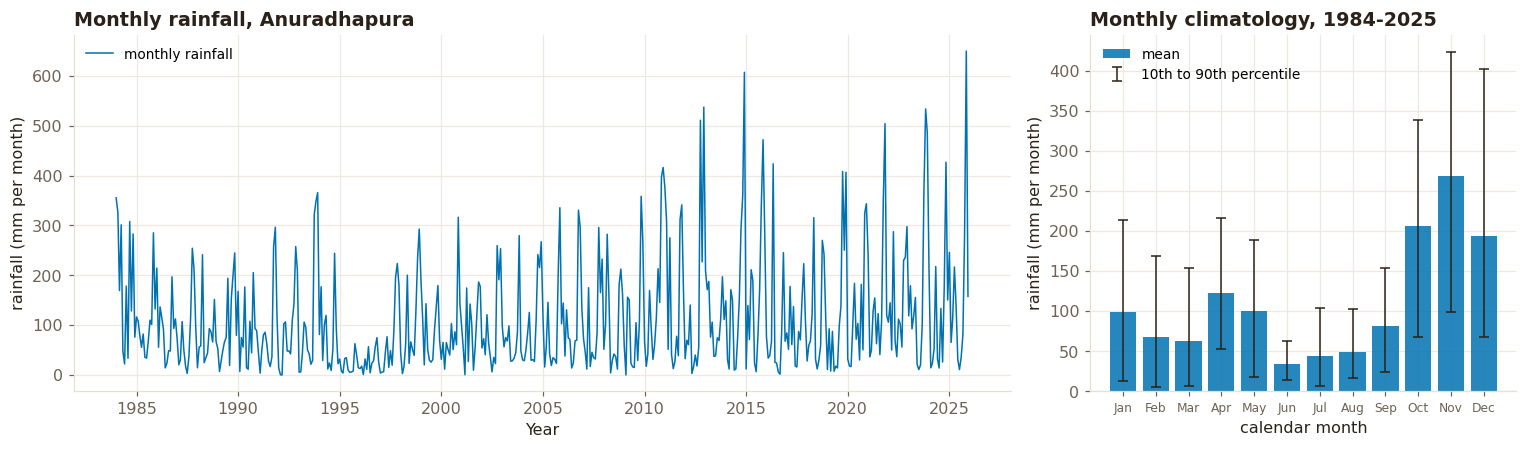

<span style='color:#6E6255'>*Left: every month of the record. Right: the typical amount for each calendar month and its year-to-year range.*</span>

In [38]:
# Monthly climatology: mean and 10th-90th percentile range for each calendar month
clim = rain.groupby("Month")["prcp"].agg(mean="mean", p10=lambda x: x.quantile(0.1), p90=lambda x: x.quantile(0.9))
view = rain[(rain["Year"] >= START_YEAR) & (rain["Year"] <= END_YEAR)]

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [2.2, 1]})
ax[0].plot(view["Date"], view["prcp"], color=theme.INDEX_COLOURS["SPI"], lw=1, label="monthly rainfall")
ax[0].set_title(f"Monthly rainfall, {DISTRICT}")
ax[0].set_xlabel("Year"); ax[0].set_ylabel("rainfall (mm per month)"); ax[0].legend()
ax[1].bar(clim.index, clim["mean"], color=theme.INDEX_COLOURS["SPI"], alpha=0.85, label="mean")
ax[1].errorbar(clim.index, clim["mean"], yerr=[clim["mean"] - clim["p10"], clim["p90"] - clim["mean"]],
               fmt="none", ecolor=theme.INK, capsize=3, lw=1, label="10th to 90th percentile")
ax[1].set_xticks(range(1, 13), [calendar.month_abbr[m] for m in range(1, 13)], fontsize=8)
ax[1].set_title("Monthly climatology, 1984-2025"); ax[1].set_xlabel("calendar month")
ax[1].set_ylabel("rainfall (mm per month)"); ax[1].legend()
plt.tight_layout(); plt.show()
nt.caption("Left: every month of the record. Right: the typical amount for each calendar month and its year-to-year range.")

#### Interpretation

In [5]:
wet, dry = clim["mean"].idxmax(), clim["mean"].idxmin()
annual = rain.groupby("Year")["prcp"].sum()
nt.interpret(f"""
{DISTRICT} receives on average **{annual.mean():.0f} mm a year** (driest year {annual.idxmin()}: {annual.min():.0f} mm,
wettest {annual.idxmax()}: {annual.max():.0f} mm). The wettest calendar month is **{calendar.month_name[wet]}**
({clim.loc[wet, 'mean']:.0f} mm on average) and the driest is **{calendar.month_name[dry]}** ({clim.loc[dry, 'mean']:.0f} mm).
This strong seasonal cycle is why SPI compares each month only with the same calendar month in other years:
{clim.loc[dry, 'mean']:.0f} mm is normal in {calendar.month_name[dry]} but would be a severe shortfall in
{calendar.month_name[wet]}, when the Maha paddy crop depends on the monsoon.
""" + (f"""

**Data check.** {annual.idxmin()} has only {annual.min():.0f} mm, {100 * annual.min() / annual.mean():.0f}% of the
average year. That year was a real drought, but a total this low is far below what rain gauges recorded, so it
may partly be an artefact of the NASA POWER product. It drives the most severe event found below; treat its
exact size with caution.""" if annual.min() < 0.35 * annual.mean() else ""))


Anuradhapura receives on average **1328 mm a year** (driest year 1995: 258 mm,
wettest 1984: 2229 mm). The wettest calendar month is **November**
(269 mm on average) and the driest is **June** (33 mm).
This strong seasonal cycle is why SPI compares each month only with the same calendar month in other years:
33 mm is normal in June but would be a severe shortfall in
November, when the Maha paddy crop depends on the monsoon.


**Data check.** 1995 has only 258 mm, 19% of the
average year. That year was a real drought, but a total this low is far below what rain gauges recorded, so it
may partly be an artefact of the NASA POWER product. It drives the most severe event found below; treat its
exact size with caution.

## 2. Aggregation at 1, 3 and 6 months

SPI-k looks at the rain that fell over the last $k$ months, so short dry spells (k = 1), a cultivation season
(k = 3) and longer water shortages (k = 6) can each be measured.

$$x_t^{(k)} = \sum_{j=0}^{k-1} P_{t-j}$$

,Year,Month,rain (mm),1-month (mm),3-month (mm),6-month (mm)
3,1984,4,301.050,301.050,796.715,NaN
4,1984,5,47.895,47.895,518.360,NaN
5,1984,6,22.050,22.050,370.995,1221.920
6,1984,7,178.405,178.405,248.350,1045.065
7,1984,8,33.480,33.480,233.935,752.295
8,1984,9,307.800,307.800,519.685,890.680


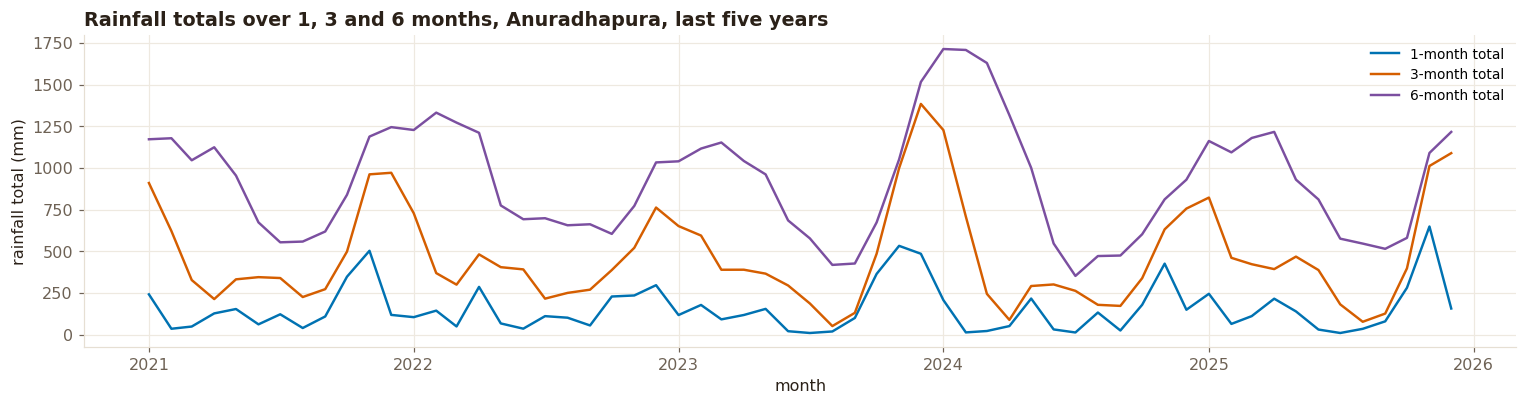

<span style='color:#6E6255'>*Longer windows smooth out single wet or dry months and follow the seasons.*</span>

In [6]:
# k-month totals ending at each month (this is step 1 of compute_spi; the first k-1 months have no value)
for k in common.SCALES:
    rain[f"sum{k}"] = rain["prcp"].rolling(k, min_periods=k).sum()
nt.show(rain[["Year", "Month", "prcp", "sum1", "sum3", "sum6"]].rename(
    columns={"prcp": "rain (mm)", "sum1": "1-month (mm)", "sum3": "3-month (mm)", "sum6": "6-month (mm)"}).iloc[3:9])

recent = rain[rain["Year"].between(max(START_YEAR, END_YEAR - 4), END_YEAR)]
fig, ax = plt.subplots(figsize=(14, 3.8))
for k, c in zip(common.SCALES, [theme.INDEX_COLOURS["SPI"], theme.INDEX_COLOURS["SSI"], theme.INDEX_COLOURS["MSDI"]]):
    ax.plot(recent["Date"], recent[f"sum{k}"], color=c, lw=1.6, label=f"{k}-month total")
ax.set_title(f"Rainfall totals over 1, 3 and 6 months, {DISTRICT}, last five years")
ax.set_xlabel("month"); ax.set_ylabel("rainfall total (mm)"); ax.legend()
plt.tight_layout(); plt.show()
nt.caption("Longer windows smooth out single wet or dry months and follow the seasons.")

#### Interpretation

In [7]:
row = rain.dropna(subset=["sum6"]).iloc[-1]
nt.interpret(f"""
For {calendar.month_name[int(row['Month'])]} {int(row['Year'])}, the last month on record, {DISTRICT} had
{row['sum1']:.0f} mm in the month, {row['sum3']:.0f} mm over 3 months and {row['sum6']:.0f} mm over 6 months.
The 3-month total is the one used below (SCALE = {SCALE}) because it matches the length of a paddy growing season.
""")


For December 2025, the last month on record, Anuradhapura had
158 mm in the month, 1090 mm over 3 months and 1217 mm over 6 months.
The 3-month total is the one used below (SCALE = 3) because it matches the length of a paddy growing season.


## 3. Distribution fitting for rainfall, per calendar month

Each calendar month's $k$-month totals (about 42 values) are fitted with six candidate distributions by maximum
likelihood, to see which one describes the rainfall best.

$$\text{Gamma: } f(x)=\frac{x^{\alpha-1}e^{-x/\beta}}{\beta^{\alpha}\Gamma(\alpha)} \qquad
\text{Weibull: } f(x)=\frac{c}{\lambda}\Big(\frac{x}{\lambda}\Big)^{c-1}e^{-(x/\lambda)^c}$$

$$\text{Log-normal: } f(x)=\frac{1}{x\sigma\sqrt{2\pi}}e^{-\frac{(\ln x-\mu)^2}{2\sigma^2}} \qquad
\text{Exponential: } f(x)=\lambda e^{-\lambda x}$$

$$\text{Beta on } (0, b):\ f(x)=\frac{(x/b)^{a_1-1}(1-x/b)^{a_2-1}}{b\,B(a_1,a_2)} \qquad
\text{GEV: } f(x)=\frac{1}{\sigma}\,t(x)^{\xi+1}e^{-t(x)},\ t(x)=\Big(1+\xi\frac{x-\mu}{\sigma}\Big)^{-1/\xi}$$

Comparison: $\text{AIC} = 2k - 2\ln L$, $\text{BIC} = k\ln n - 2\ln L$ (lower is better) and the
Kolmogorov-Smirnov statistic $D_n=\sup_x|F_n(x)-F(x)|$ (a large p-value means the fit is not rejected).

In [8]:
FAMILIES = ("gamma", "weibull_min", "lognorm", "expon", "beta", "genextreme")
total = rain[f"sum{SCALE}"]

# Best and runner-up family for every calendar month
winners = mc.per_month_winners(total, rain["Month"], FAMILIES)
winners["month"] = winners["month"].map(lambda m: calendar.month_abbr[m])
nt.show(winners)

,month,best,runner-up,AIC best,AIC gap Gamma - best,KS p best
0,Jan,Weibull,Gamma,574.9,1.5,0.978
1,Feb,Gamma,Weibull,553.1,0.0,0.951
2,Mar,Gamma,Weibull,538.6,0.0,0.991
3,Apr,Gamma,Log-normal,534.0,0.0,0.935
4,May,Weibull,GEV,522.7,3.4,0.843
5,Jun,Gamma,Weibull,504.5,0.0,0.982
6,Jul,Gamma,Log-normal,498.2,0.0,0.825
7,Aug,Gamma,Log-normal,462.3,0.0,0.897
8,Sep,Gamma,Weibull,498.6,0.0,0.802
9,Oct,Weibull,GEV,531.5,2.6,0.986


In [9]:
# Worked month: the calendar month of the driest SPI on record (used again in step 5)
spi = compute_spi(rain[["Year", "Month", "prcp"]], scale=SCALE)
spi["Date"] = pd.to_datetime(spi[["Year", "Month"]].assign(day=1))
col = f"SPI{SCALE}"
ex = spi.loc[spi[col].idxmin()]
EX_MONTH = int(ex["Month"])
x_month = total[(rain["Month"] == EX_MONTH)].dropna()
x_month = x_month[x_month > 0].to_numpy()
fits, frozen = mc.fit_families(x_month, FAMILIES)
print(f"{SCALE}-month totals ending in {calendar.month_name[EX_MONTH]}: n = {len(x_month)}")
nt.show(fits.drop(columns="scipy"))

3-month totals ending in November: n = 42


,family,parameters,log L,k,AIC,BIC,KS D,KS p
0,Weibull,"2.838, 0, 624.5",-283.827,2,571.654,575.130,0.103,0.724
1,GEV,"0.1781, 473.7, 194.3",-283.437,3,572.874,578.087,0.088,0.874
2,Gamma,"6.183, 0, 90.04",-284.503,2,573.006,576.482,0.081,0.923
3,Beta,"2.294, 1.87, 0, 1037",-285.443,3,576.887,582.100,0.164,0.188
4,Log-normal,"0.4378, 0, 512.3",-286.933,2,577.867,581.342,0.094,0.814
5,Exponential,"0, 556.7",-307.522,1,617.043,618.781,0.381,0.000


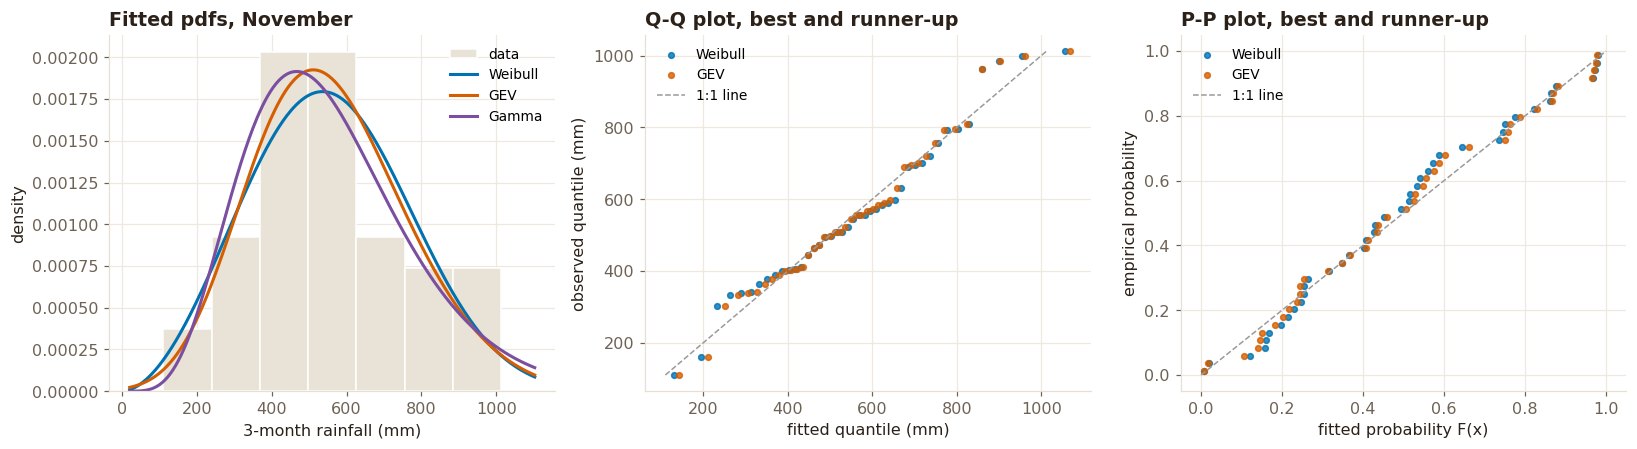

<span style='color:#6E6255'>*Points close to the dashed 1:1 line mean the distribution reproduces the observed rainfall well.*</span>

In [10]:
best, second = fits.loc[0, "scipy"], fits.loc[1, "scipy"]
names = [best, second] + (["gamma"] if "gamma" not in (best, second) else [])
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
nt.hist_with_fits(ax[0], x_month, {mc.FAMILY_NAMES[n]: frozen[n] for n in names}, [mc.FAMILY_NAMES[n] for n in names],
                  f"Fitted pdfs, {calendar.month_name[EX_MONTH]}", f"{SCALE}-month rainfall (mm)")
pair = {mc.FAMILY_NAMES[best]: frozen[best], mc.FAMILY_NAMES[second]: frozen[second]}
nt.qq_plot(ax[1], x_month, pair, "Q-Q plot, best and runner-up", "mm")
nt.pp_plot(ax[2], x_month, pair, "P-P plot, best and runner-up")
plt.tight_layout(); plt.show()
nt.caption("Points close to the dashed 1:1 line mean the distribution reproduces the observed rainfall well.")

#### Interpretation

In [11]:
counts = winners["best"].value_counts()
gap = winners["AIC gap Gamma - best"]
g_row = fits[fits["scipy"] == "gamma"].iloc[0]
nt.interpret(f"""
Across the 12 calendar months the lowest AIC goes to {', '.join(f'**{k}** ({v})' for k, v in counts.items())}.
Gamma is either the best or close behind: its AIC is on average **{gap.mean():.1f}** points above the winner
(largest gap {gap.max():.1f}); a gap below about 2 means the two fits are practically equal. For
{calendar.month_name[EX_MONTH]} the winner is **{fits.loc[0, 'family']}** (AIC {fits.loc[0, 'AIC']:.1f}) and Gamma
has AIC {g_row['AIC']:.1f} with KS p = {g_row['KS p']:.2f}, so Gamma is not rejected.

**Why Gamma is kept for the SPI.** McKee et al. (1993) and the WMO SPI guide define SPI with the Gamma
distribution, so keeping it makes these SPI values comparable with every published SPI study, including the Sri
Lankan ones. With about 42 values per month the AIC differences above are small and would change from one
sample to the next, so switching family month by month would add noise rather than accuracy.
""")


Across the 12 calendar months the lowest AIC goes to **Gamma** (7), **Weibull** (5).
Gamma is either the best or close behind: its AIC is on average **0.8** points above the winner
(largest gap 3.4); a gap below about 2 means the two fits are practically equal. For
November the winner is **Weibull** (AIC 571.7) and Gamma
has AIC 573.0 with KS p = 0.92, so Gamma is not rejected.

**Why Gamma is kept for the SPI.** McKee et al. (1993) and the WMO SPI guide define SPI with the Gamma
distribution, so keeping it makes these SPI values comparable with every published SPI study, including the Sri
Lankan ones. With about 42 values per month the AIC differences above are small and would change from one
sample to the next, so switching family month by month would add noise rather than accuracy.


## 4. Zero-rainfall months

A month with no rain cannot come from a Gamma distribution, so the standard SPI uses a mixed distribution:
a probability $q$ of exactly zero and a Gamma for the rest.

$$H(x) = q + (1-q)\,G(x), \qquad q = \frac{\text{number of zero totals}}{n}$$

In [12]:
# Zero totals per calendar month at this scale
zeros = (pd.DataFrame({"Month": rain["Month"], "total": total}).dropna()
         .assign(zero=lambda d: d["total"] <= 0).groupby("Month")["zero"].agg(["sum", "count"]))
zeros["q"] = zeros["sum"] / zeros["count"]
zeros.index = [calendar.month_abbr[m] for m in zeros.index]
nt.show(zeros.rename(columns={"sum": "zero totals", "count": "years"}).T)
print("Zero months in the raw monthly series:", int((rain["prcp"] <= 0).sum()), "of", len(rain))

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
zero totals,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
years,41.0,41.0,42.0,42.0,42.0,42.0,42.0,42.0,42.0,42.0,42.0,42.0
q,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Zero months in the raw monthly series: 2 of 504


#### Interpretation

In [13]:
nz = int(zeros["zero totals"].sum()) if "zero totals" in zeros else int(zeros["sum"].sum())
nt.interpret(f"""
At the {SCALE}-month scale {DISTRICT} has **{nz}** zero totals in the whole record, and the raw monthly series has
{int((rain['prcp'] <= 0).sum())} zero months out of {len(rain)}, because a district average over many grid cells
almost always catches some rain. So q is {'0 for every calendar month' if nz == 0 else 'very small'}.
The project's `compute_spi` does not use the mixed form: it replaces any zero by 0.001 mm before the Gamma fit,
so H(x) = G(x). With so few zeros the two give practically the same SPI.
""")


At the 3-month scale Anuradhapura has **0** zero totals in the whole record, and the raw monthly series has
2 zero months out of 504, because a district average over many grid cells
almost always catches some rain. So q is 0 for every calendar month.
The project's `compute_spi` does not use the mixed form: it replaces any zero by 0.001 mm before the Gamma fit,
so H(x) = G(x). With so few zeros the two give practically the same SPI.


## 5. SPI calculation and drought classes

The fitted probability is turned into a standard normal score, so that 0 is normal, negative is drier than
normal and the same value means the same rarity in every district and season.

$$\text{SPI} = \Phi^{-1}\big(H(x)\big)$$

with $\Phi^{-1}$ the inverse of the standard normal CDF. The fitted probability is kept inside
$(10^{-4},\ 1-10^{-4})$, so SPI lies between -3.72 and +3.72.

In [14]:
# Worked example: redo the last two steps for the driest month and check against compute_spi
x = float(total[(rain["Year"] == ex["Year"]) & (rain["Month"] == EX_MONTH)].iloc[0])
sample = total[rain["Month"] == EX_MONTH].dropna().to_numpy().copy()
sample[sample <= 0] = 0.001                               # as compute_spi does
alpha, _, beta = stats.gamma.fit(sample, floc=0)
G = float(np.clip(stats.gamma.cdf(max(x, 0.001), alpha, scale=beta), 1e-4, 1 - 1e-4))
worked = pd.DataFrame([{"month": f"{calendar.month_abbr[EX_MONTH]} {int(ex['Year'])}", f"{SCALE}-month total (mm)": x,
                        "Gamma alpha": alpha, "Gamma beta (mm)": beta, "G(x)": G, "SPI = Phi^-1(G)": stats.norm.ppf(G),
                        "SPI from compute_spi": ex[col]}])
nt.show(worked, 4)
print("Same as the module:", np.isclose(stats.norm.ppf(G), ex[col]))
nt.show(nt.class_table())

,month,3-month total (mm),Gamma alpha,Gamma beta (mm),G(x),SPI = Phi^-1(G),SPI from compute_spi
0,Nov 1995,110.925,6.1825,90.037,0.0013,-3.0226,-3.0226


Same as the module: True


,class,index range,colour
0,Extremely wet,>= 2,#08306B
1,Very wet,1.5 to 2,#2171B5
2,Moderately wet,1 to 1.5,#6BAED6
3,Near normal,-1 to 1,#EDE8DF
4,Moderately dry,-1.5 to -1,#F4A259
5,Severely dry,-2 to -1.5,#C4561D
6,Extremely dry,<= -2,#7A2E0B


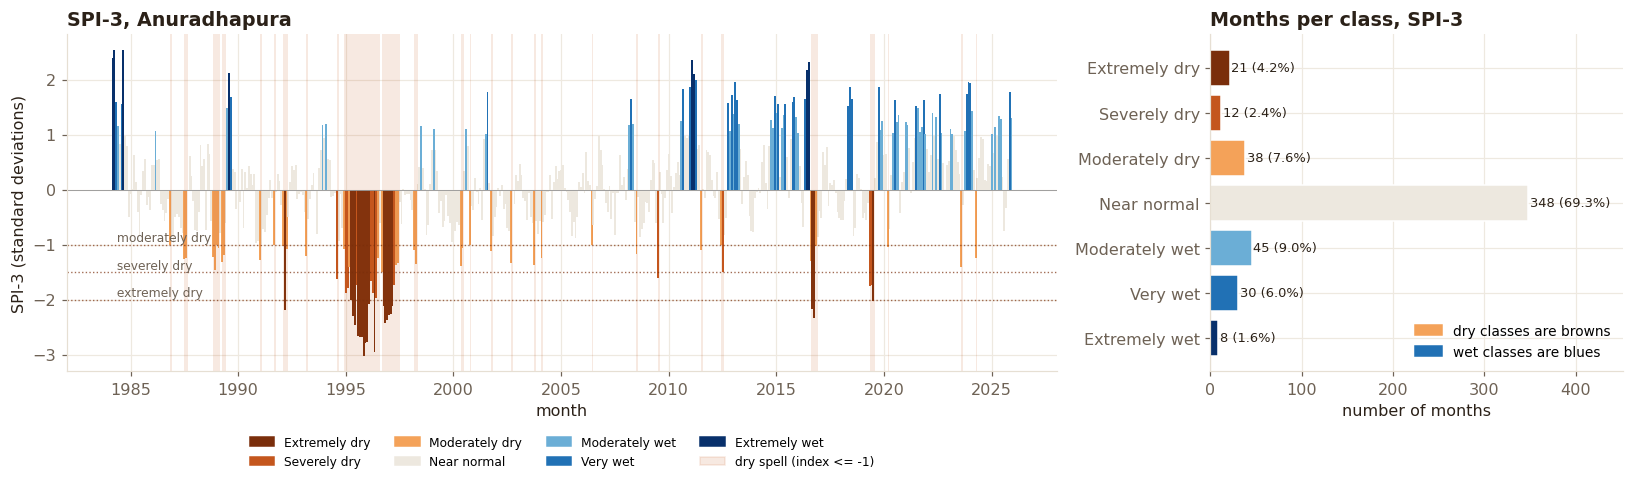

<span style='color:#6E6255'>*Brown bars are drier than normal, blue wetter; shaded spans are dry spells (SPI at or below -1).*</span>

In [15]:
view = spi[(spi["Year"] >= START_YEAR) & (spi["Year"] <= END_YEAR)].dropna(subset=[col])
fig, ax = plt.subplots(1, 2, figsize=(15, 4.6), gridspec_kw={"width_ratios": [2.4, 1]})
nt.index_bars(ax[0], view["Date"], view[col], f"SPI-{SCALE}", f"SPI-{SCALE}, {DISTRICT}")
counts = nt.class_frequency(ax[1], spi[col], f"Months per class, SPI-{SCALE}")
plt.tight_layout(); plt.show()
nt.caption("Brown bars are drier than normal, blue wetter; shaded spans are dry spells (SPI at or below -1).")

#### Interpretation

In [16]:
dry = int(counts[["Moderately dry", "Severely dry", "Extremely dry"]].sum())
nt.interpret(f"""
The driest {SCALE}-month period on record ended in **{calendar.month_name[EX_MONTH]} {int(ex['Year'])}**: only
{x:.0f} mm fell, which has probability G = {G:.4f} under that month's Gamma (alpha = {alpha:.2f}, beta = {beta:.1f} mm),
giving **SPI = {ex[col]:.2f}**, extremely dry. Over the whole record **{dry} of {int(counts.sum())} months
({100 * dry / counts.sum():.1f}%)** are moderately dry or worse (SPI at or below -1), close to the 16% a standard normal
index should give. {int(counts['Extremely dry'])} months are extremely dry: those are the periods when rain-fed paddy
is most at risk.
""")


The driest 3-month period on record ended in **November 1995**: only
111 mm fell, which has probability G = 0.0013 under that month's Gamma (alpha = 6.18, beta = 90.0 mm),
giving **SPI = -3.02**, extremely dry. Over the whole record **71 of 502 months
(14.1%)** are moderately dry or worse (SPI at or below -1), close to the 16% a standard normal
index should give. 21 months are extremely dry: those are the periods when rain-fed paddy
is most at risk.


## 6. Is the SPI standard normal?

If the Gamma fits are right, SPI should have mean 0 and standard deviation 1, and follow the normal curve. This
is what makes the McKee class cut-offs mean the same thing everywhere.

$$\bar z = \frac{1}{n}\sum z_t \approx 0,\qquad s = \sqrt{\tfrac{1}{n-1}\sum (z_t-\bar z)^2} \approx 1$$

,n,mean,SD,skewness,Shapiro-Wilk W,Shapiro-Wilk p
0,502,0.001,1.001,-0.221,0.992,0.006


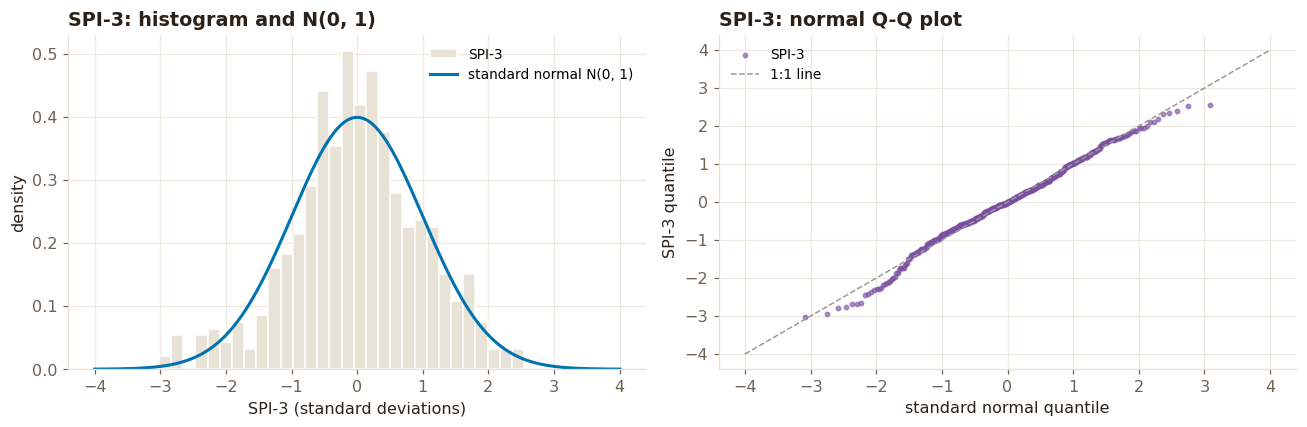

<span style='color:#6E6255'>*The histogram should follow the blue curve and the Q-Q points should lie on the dashed line.*</span>

In [17]:
z = spi[col].dropna()
sw = stats.shapiro(z)
norm_tab = pd.DataFrame([{"n": len(z), "mean": z.mean(), "SD": z.std(), "skewness": stats.skew(z),
                          "Shapiro-Wilk W": sw.statistic, "Shapiro-Wilk p": sw.pvalue}])
nt.show(norm_tab)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
nt.normal_check(ax, z, f"SPI-{SCALE}")
plt.tight_layout(); plt.show()
nt.caption("The histogram should follow the blue curve and the Q-Q points should lie on the dashed line.")

#### Interpretation

In [18]:
nt.interpret(f"""
SPI-{SCALE} for {DISTRICT} has mean **{z.mean():+.3f}** and standard deviation **{z.std():.3f}**, very close to 0 and 1.
The Shapiro-Wilk p-value is {sw.pvalue:.3g}{' (it rejects exact normality, which with ' + str(len(z)) + ' months picks up even small departures, mostly the capped tails at -3.72 and +3.72)' if sw.pvalue < 0.05 else ', so normality is not rejected'}.
For drought monitoring what matters is the mean and spread and the left tail, and the Q-Q plot shows the dry tail
follows the normal line, so the McKee classes can be read as intended.
""")


SPI-3 for Anuradhapura has mean **+0.001** and standard deviation **1.001**, very close to 0 and 1.
The Shapiro-Wilk p-value is 0.00586 (it rejects exact normality, which with 502 months picks up even small departures, mostly the capped tails at -3.72 and +3.72).
For drought monitoring what matters is the mean and spread and the left tail, and the Q-Q plot shows the dry tail
follows the normal line, so the McKee classes can be read as intended.


## 7. Run theory: drought events, duration and severity

A drought event is a continuous run of months with SPI below the threshold $X_0 = 0$. Its duration is the
number of months and its severity the accumulated deficit (Shiau 2006).

$$D = t_e - t_s + 1,\qquad S = \sum_{t=t_s}^{t_e}\lvert \text{SPI}_t\rvert,\qquad
E(L) = \frac{\text{months in the record}}{\text{number of events}}$$

$E(L)$ is the mean inter-arrival time between events, used later for return periods.

In [19]:
# The same call the dashboard makes: SPI -> events -> duration-severity model
model, spi_df, events = build_district_model(rain[["Year", "Month", "prcp"]], DISTRICT, SCALE)
print(f"{model.n_events} events, E(L) = {model.EL_months:.2f} months")
nt.show(events.head(6))
top = events.sort_values("Severity", ascending=False).head(10)
nt.show(top)

58 events, E(L) = 8.69 months


,StartYear,StartMonth,EndYear,EndMonth,Duration,Severity
0,1984,12,1985,1,2,0.585
1,1985,5,1985,7,3,1.347
2,1985,10,1985,12,3,0.808
3,1986,6,1987,9,16,10.097
4,1987,12,1988,3,4,2.115
5,1988,7,1988,7,1,0.728


,StartYear,StartMonth,EndYear,EndMonth,Duration,Severity
14,1994,5,1997,8,40,67.660
3,1986,6,1987,9,16,10.097
17,1999,5,2000,6,14,9.440
6,1988,10,1989,6,9,9.259
46,2016,8,2017,2,7,8.603
24,2003,4,2004,6,15,7.830
50,2019,1,2019,7,7,7.278
9,1990,11,1991,6,8,6.267
11,1992,1,1992,5,5,5.066
32,2008,6,2009,2,9,4.995


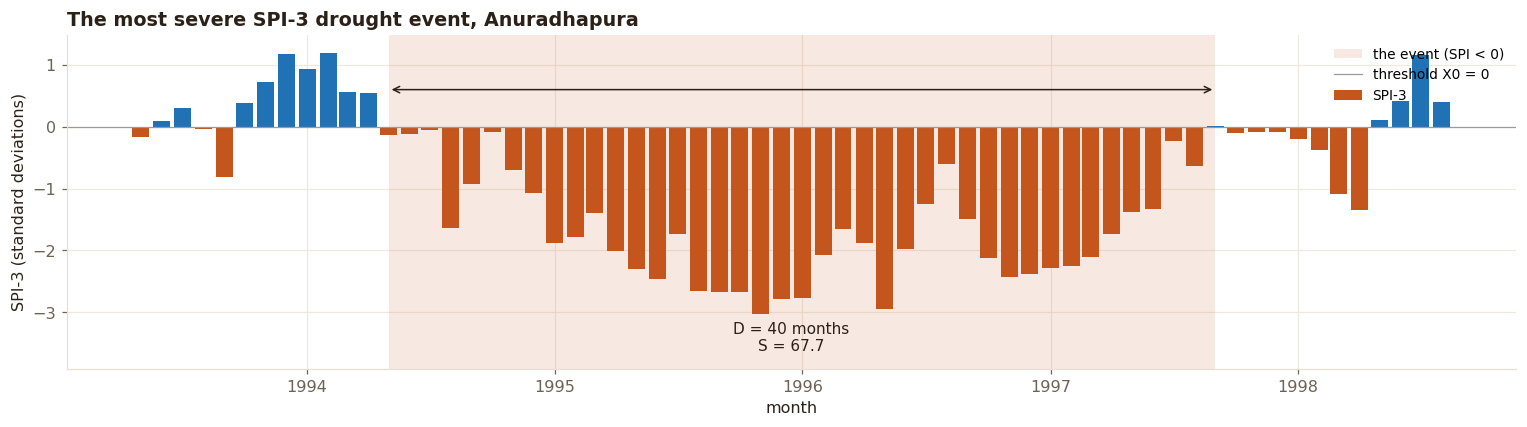

<span style='color:#6E6255'>*The arrow spans the duration; the severity adds up the depth of every brown bar inside the shaded span.*</span>

In [20]:
# Annotated timeline of the worst event, with a year either side
w = events.loc[events["Severity"].idxmax()]
start, end = pd.Timestamp(int(w["StartYear"]), int(w["StartMonth"]), 1), pd.Timestamp(int(w["EndYear"]), int(w["EndMonth"]), 1)
win = spi[(spi["Date"] >= start - pd.DateOffset(months=12)) & (spi["Date"] <= end + pd.DateOffset(months=12))]
fig, ax = plt.subplots(figsize=(14, 4))
ax.bar(win["Date"], win[col], width=25, color=np.where(win[col] < 0, theme.CLASS_COLOURS["Severely dry"],
                                                     theme.CLASS_COLOURS["Very wet"]), label=f"SPI-{SCALE}")
ax.axvspan(start, end + pd.offsets.MonthBegin(1), color=theme.DRY_SHADE, lw=0, label="the event (SPI < 0)")
ax.axhline(0, color="#9A9A9A", lw=0.8, label="threshold X0 = 0")
ax.annotate(f"D = {int(w['Duration'])} months\nS = {w['Severity']:.1f}", xy=(start + (end - start) / 2, win[col].min()),
            xytext=(0, -5), textcoords="offset points", ha="center", va="top", fontsize=10, color=theme.INK)
ax.annotate("", xy=(start, 0.6), xytext=(end + pd.offsets.MonthBegin(1), 0.6),
            arrowprops=dict(arrowstyle="<->", color=theme.INK))
ax.set_ylim(win[col].min() - 0.9, max(win[col].max(), 1) + 0.3)
ax.set_title(f"The most severe SPI-{SCALE} drought event, {DISTRICT}")
ax.set_xlabel("month"); ax.set_ylabel(f"SPI-{SCALE} (standard deviations)"); ax.legend(loc="upper right")
plt.tight_layout(); plt.show()
nt.caption("The arrow spans the duration; the severity adds up the depth of every brown bar inside the shaded span.")

#### Interpretation

In [21]:
starts = pd.to_datetime(dict(year=events["StartYear"], month=events["StartMonth"], day=1))
nt.interpret(f"""
SPI-{SCALE} splits the {len(spi_df)} months of {DISTRICT} into **{model.n_events} drought events**, one every
{model.EL_months:.1f} months on average (E(L)). Most are short: the median lasts {events['Duration'].median():.0f}
months. The worst ran from **{start:%b %Y} to {end:%b %Y}**, {int(w['Duration'])} months with severity
{w['Severity']:.1f}, which covers several Maha and Yala seasons in a row. Events are counted from SPI < 0, so they
include mild dry spells; the dry months of step 5 (SPI at or below -1) are the deeper part of them.
""")


SPI-3 splits the 504 months of Anuradhapura into **58 drought events**, one every
8.7 months on average (E(L)). Most are short: the median lasts 2
months. The worst ran from **May 1994 to Aug 1997**, 40 months with severity
67.7, which covers several Maha and Yala seasons in a row. Events are counted from SPI < 0, so they
include mild dry spells; the dry months of step 5 (SPI at or below -1) are the deeper part of them.


## 8. Marginal distributions of duration and severity

Duration and severity each need their own distribution before they can be joined. Four candidates are compared
for each.

$$\text{Exponential: } f_D(d)=\lambda e^{-\lambda d},\ \hat\lambda = 1/\bar D \qquad
\text{Gamma: } f_S(s)=\frac{s^{\alpha-1}e^{-s/\beta}}{\beta^\alpha\Gamma(\alpha)}$$

Weibull and Log-normal as in step 3. Comparison by AIC, BIC and the KS test.

In [22]:
MARG = ("expon", "gamma", "weibull_min", "lognorm")
fit_d, frozen_d = mc.fit_families(events["Duration"].astype(float), MARG)
fit_s, frozen_s = mc.fit_families(events["Severity"].astype(float), MARG)
print("Duration D"); nt.show(fit_d.drop(columns="scipy"))
print("Severity S"); nt.show(fit_s.drop(columns="scipy"))
print(f"Used by the model: D ~ Exponential(lambda = {model.marginals.lambda_d:.4f}), "
      f"S ~ Gamma(alpha = {model.marginals.alpha_s:.3f}, beta = {model.marginals.beta_s:.3f})")

Duration D


,family,parameters,log L,k,AIC,BIC,KS D,KS p
0,Log-normal,"0.912, 0, 2.677",-134.058,2,272.116,276.237,0.187,0.030
1,Exponential,"0, 4.345",-143.201,1,288.402,290.463,0.206,0.013
2,Gamma,"1.171, 0, 3.712",-142.769,2,289.537,293.658,0.196,0.020
3,Weibull,"0.9924, 0, 4.327",-143.198,2,290.395,294.516,0.208,0.011


Severity S


,family,parameters,log L,k,AIC,BIC,KS D,KS p
0,Log-normal,"1.495, 0, 1.102",-111.253,2,226.506,230.627,0.060,0.977
1,Weibull,"0.6723, 0, 2.303",-115.412,2,234.825,238.946,0.094,0.646
2,Gamma,"0.5618, 0, 5.957",-119.868,2,243.736,247.857,0.149,0.136
3,Exponential,"0, 3.346",-128.054,1,258.109,260.169,0.232,0.003


Used by the model: D ~ Exponential(lambda = 0.2302), S ~ Gamma(alpha = 0.562, beta = 5.957)


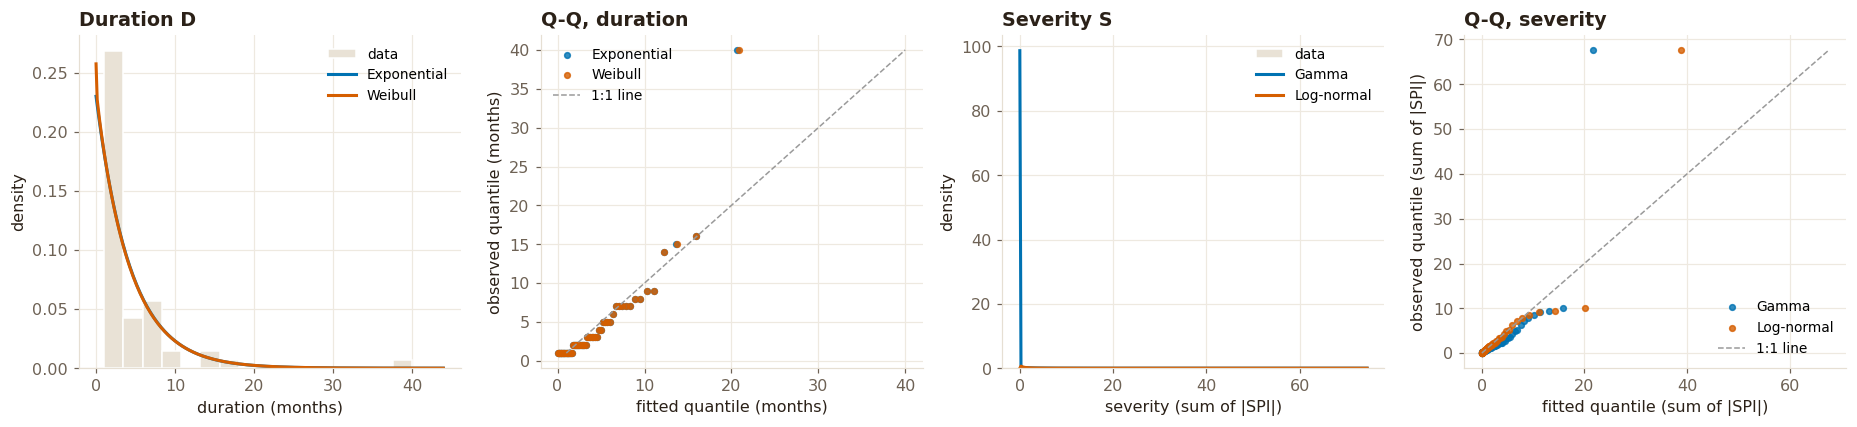

<span style='color:#6E6255'>*Both variables have many small values and a long tail; the Q-Q plots show how well each family follows the tail.*</span>

In [23]:
fig, ax = plt.subplots(1, 4, figsize=(17, 4))
nt.hist_with_fits(ax[0], events["Duration"], {mc.FAMILY_NAMES[n]: frozen_d[n] for n in MARG if n in frozen_d},
                  [mc.FAMILY_NAMES[n] for n in ("expon", "weibull_min") if n in frozen_d], "Duration D", "duration (months)")
nt.qq_plot(ax[1], events["Duration"], {"Exponential": frozen_d["expon"], "Weibull": frozen_d["weibull_min"]},
           "Q-Q, duration", "months")
nt.hist_with_fits(ax[2], events["Severity"], {mc.FAMILY_NAMES[n]: frozen_s[n] for n in MARG if n in frozen_s},
                  [mc.FAMILY_NAMES[n] for n in ("gamma", "lognorm") if n in frozen_s], "Severity S", "severity (sum of |SPI|)")
nt.qq_plot(ax[3], events["Severity"], {"Gamma": frozen_s["gamma"], "Log-normal": frozen_s["lognorm"]},
           "Q-Q, severity", "sum of |SPI|")
plt.tight_layout(); plt.show()
nt.caption("Both variables have many small values and a long tail; the Q-Q plots show how well each family follows the tail.")

#### Interpretation

In [24]:
e_row, g_row = fit_d[fit_d["scipy"] == "expon"].iloc[0], fit_s[fit_s["scipy"] == "gamma"].iloc[0]
nt.interpret(f"""
For duration the lowest AIC is **{fit_d.loc[0, 'family']}** ({fit_d.loc[0, 'AIC']:.1f}); Exponential has AIC
{e_row['AIC']:.1f} and KS p = {e_row['KS p']:.3f}. For severity the lowest AIC is **{fit_s.loc[0, 'family']}**
({fit_s.loc[0, 'AIC']:.1f}); Gamma has AIC {g_row['AIC']:.1f} and KS p = {g_row['KS p']:.3f}.
Duration is a whole number of months, so the KS test on it is only approximate (ties make it strict).

The method keeps **Exponential for D and Gamma for S**, the pairing of Shiau (2006) and Ekanayake and Perera (2014)
for Sri Lanka: the Exponential describes a run that ends with the same chance every month, and the Gamma a sum of
positive deficits. Keeping the published pairing makes the return periods comparable with those studies; the AIC
differences seen here are the price, and they are reported rather than hidden.
""")


For duration the lowest AIC is **Log-normal** (272.1); Exponential has AIC
288.4 and KS p = 0.013. For severity the lowest AIC is **Log-normal**
(226.5); Gamma has AIC 243.7 and KS p = 0.136.
Duration is a whole number of months, so the KS test on it is only approximate (ties make it strict).

The method keeps **Exponential for D and Gamma for S**, the pairing of Shiau (2006) and Ekanayake and Perera (2014)
for Sri Lanka: the Exponential describes a run that ends with the same chance every month, and the Gamma a sum of
positive deficits. Keeping the published pairing makes the return periods comparable with those studies; the AIC
differences seen here are the price, and they are reported rather than hidden.


## 9. Dependence between duration and severity

Long droughts are usually also severe ones; rank correlations measure how strongly, without assuming any
distribution.

$$\tau = \frac{n_c - n_d}{\binom{n}{2}},\qquad
\rho_S = 1 - \frac{6\sum_i d_i^2}{n(n^2-1)},\qquad
(\hat U_i, \hat V_i) = \Big(\frac{R_i}{n+1}, \frac{S_i}{n+1}\Big)$$

$n_c$, $n_d$ are the concordant and discordant pairs, $d_i$ the rank differences, and $R_i$, $S_i$ the ranks
of $D_i$ and $S_i$ (the pseudo-observations).

Kendall tau = 0.759, Spearman rho = 0.892


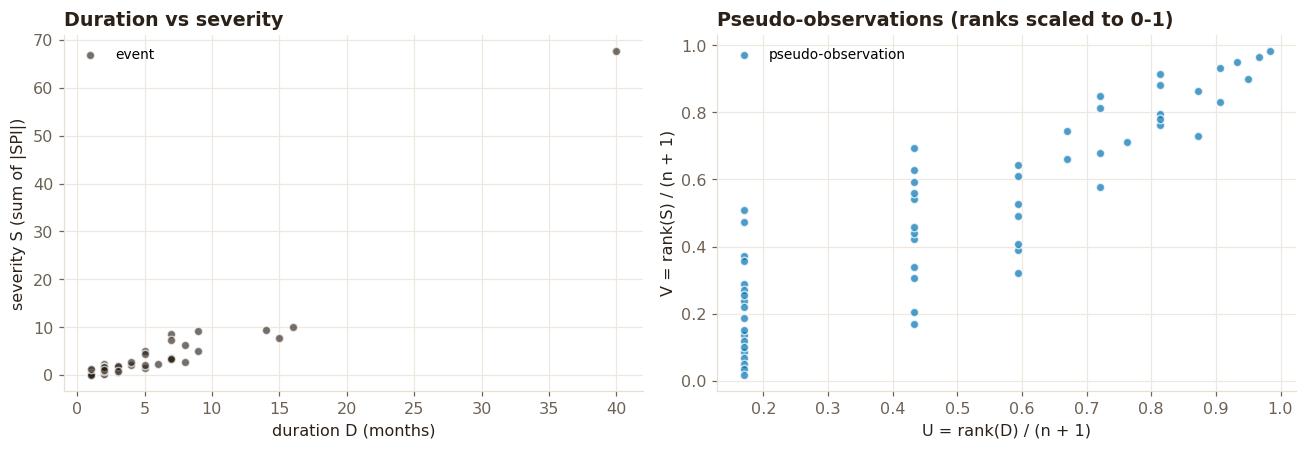

<span style='color:#6E6255'>*Ranks remove the units and the skew, leaving only how the two variables move together.*</span>

In [25]:
U = mc.M.pseudo_obs(events["Duration"].values)
V = mc.M.pseudo_obs(events["Severity"].values)
print(f"Kendall tau = {model.kendall_tau:.3f}, Spearman rho = {model.spearman_rho:.3f}")
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].scatter(events["Duration"], events["Severity"], s=30, color=theme.INK, alpha=0.65, edgecolor="white", label="event")
ax[0].set_title("Duration vs severity"); ax[0].set_xlabel("duration D (months)"); ax[0].set_ylabel("severity S (sum of |SPI|)")
ax[0].legend()
ax[1].scatter(U, V, s=30, color=theme.INDEX_COLOURS["SPI"], alpha=0.7, edgecolor="white", label="pseudo-observation")
ax[1].set_title("Pseudo-observations (ranks scaled to 0-1)"); ax[1].set_xlabel("U = rank(D) / (n + 1)")
ax[1].set_ylabel("V = rank(S) / (n + 1)"); ax[1].legend()
plt.tight_layout(); plt.show()
nt.caption("Ranks remove the units and the skew, leaving only how the two variables move together.")

#### Interpretation

In [26]:
nt.interpret(f"""
Kendall's tau is **{model.kendall_tau:.2f}** and Spearman's rho **{model.spearman_rho:.2f}**: a strong positive link.
In {DISTRICT}, knowing that a drought has lasted many months tells you it has very likely built up a large deficit,
which matters for paddy because a long drought hits several growth stages. This dependence is why duration and
severity cannot be treated as independent when asking how often a long *and* severe drought happens.
""")


Kendall's tau is **0.76** and Spearman's rho **0.89**: a strong positive link.
In Anuradhapura, knowing that a drought has lasted many months tells you it has very likely built up a large deficit,
which matters for paddy because a long drought hits several growth stages. This dependence is why duration and
severity cannot be treated as independent when asking how often a long *and* severe drought happens.


## 10. Copula selection

Sklar's theorem joins the two marginals through a copula $C$, which holds only the dependence:
$F(d,s) = C\big(F_D(d), F_S(s)\big)$.

$$\text{Gumbel-Hougaard: } C=\exp\!\Big(-\big[(-\ln u)^\theta+(-\ln v)^\theta\big]^{1/\theta}\Big),\ \theta\ge1,\quad \lambda_U = 2-2^{1/\theta}$$

$$\text{Clayton: } C=\big(u^{-\theta}+v^{-\theta}-1\big)^{-1/\theta},\ \theta>0,\quad \lambda_L = 2^{-1/\theta}$$

$$\text{Frank: } C=-\tfrac1\theta\ln\!\Big(1+\tfrac{(e^{-\theta u}-1)(e^{-\theta v}-1)}{e^{-\theta}-1}\Big),\quad \lambda_U=\lambda_L=0$$

$$\text{Gaussian (check): } C=\Phi_2\big(\Phi^{-1}(u),\Phi^{-1}(v);\rho\big),\quad \lambda_U=\lambda_L=0$$

$\theta$ maximises $\ell(\theta)=\sum_i\ln c(u_i,v_i;\theta)$; selection by lowest AIC (as in the dashboard).
The Cramer-von Mises statistic $S_n=\sum_i[C_n(\hat U_i,\hat V_i)-C_\theta(\hat U_i,\hat V_i)]^2$ with a parametric
bootstrap gives a goodness-of-fit p-value (Genest et al. 2009).

In [27]:
cop = mc.ds_copula_table(model, events, n_boot=N_BOOT)
nt.show(cop, 4)

,family,theta,log L,AIC,BIC,lambda_U,lambda_L,CvM p,selected
0,Gumbel,3.1962,42.1381,-82.2762,-80.2157,0.7578,0.0000,0.001,
1,Clayton,3.8302,37.7855,-73.5709,-71.5105,0.0000,0.8345,0.001,
2,Frank,14.0637,47.7947,-93.5895,-91.5290,0.0000,0.0000,0.001,yes
3,Gaussian (check),0.9255,53.0535,-104.1070,-102.0465,0.0000,0.0000,0.001,


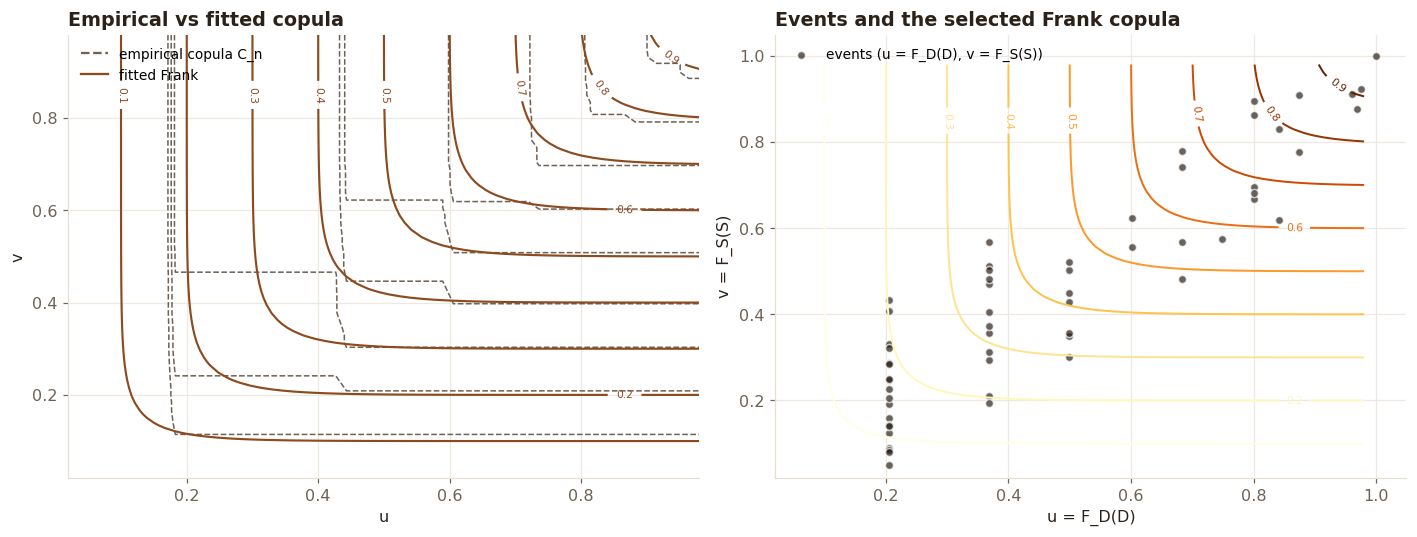

<span style='color:#6E6255'>*Where the dashed and solid contours lie close together the copula reproduces the observed dependence.*</span>

In [28]:
g = np.linspace(0.02, 0.98, 60)
GU, GV = np.meshgrid(g, g)
emp = mc.empirical_copula_grid(events["Duration"].values, events["Severity"].values, g)
fitted = np.asarray(_copula_cdf(model.best_family, GU.ravel(), GV.ravel(), model.best_theta)).reshape(GU.shape)
u = model.marginals.F_D(events["Duration"].values); v = model.marginals.F_S(events["Severity"].values)

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
levels = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
c1 = ax[0].contour(g, g, emp, levels=levels, colors=theme.MUTED, linestyles="--", linewidths=1)
c2 = ax[0].contour(GU, GV, fitted, levels=levels, colors=theme.ACCENT, linewidths=1.4)
ax[0].clabel(c2, fontsize=7)
ax[0].plot([], [], color=theme.MUTED, ls="--", label="empirical copula C_n"); ax[0].plot([], [], color=theme.ACCENT, label=f"fitted {model.best_family}")
ax[0].set_title("Empirical vs fitted copula"); ax[0].set_xlabel("u"); ax[0].set_ylabel("v"); ax[0].legend(loc="upper left")
c3 = ax[1].contour(GU, GV, fitted, levels=levels, cmap="YlOrBr", linewidths=1.3)
ax[1].clabel(c3, fontsize=7)
ax[1].scatter(u, v, s=28, color=theme.INK, alpha=0.7, edgecolor="white", label="events (u = F_D(D), v = F_S(S))")
ax[1].set_title(f"Events and the selected {model.best_family} copula"); ax[1].set_xlabel("u = F_D(D)"); ax[1].set_ylabel("v = F_S(S)")
ax[1].legend(loc="upper left")
plt.tight_layout(); plt.show()
nt.caption("Where the dashed and solid contours lie close together the copula reproduces the observed dependence.")

#### Interpretation

In [29]:
sel = cop[cop["selected"] == "yes"].iloc[0]
gauss = cop[cop["family"].str.startswith("Gaussian")].iloc[0]
others = cop[(cop["selected"] != "yes") & ~cop["family"].str.startswith("Gaussian")]
nt.interpret(f"""
The selected copula is **{sel['family']}** with theta = {sel['theta']:.3f} (AIC {sel['AIC']:.1f}, BIC {sel['BIC']:.1f}),
against {', '.join(f"{r['family']} AIC {r['AIC']:.1f}" for _, r in others.iterrows())}. Its Cramer-von Mises
bootstrap p-value is {sel['CvM p']:.3f}, so it is {'not rejected' if sel['CvM p'] >= 0.05 else 'rejected at the 5% level (the best family available is still used)'}.
Tail dependence: lambda_U = {sel['lambda_U']:.3f}, lambda_L = {sel['lambda_L']:.3f}.
The Gaussian check gives AIC {gauss['AIC']:.1f}, {'lower than the selected family: it fits these events better, but it is kept as a check only because the method follows the drought-copula literature (Shiau 2006) with Gumbel, Clayton and Frank, and the dashboard uses the same three' if gauss['AIC'] < sel['AIC'] else 'not lower than the selected family, so the three classical drought copulas are enough'}.
The bootstrap test rejects {int((cop['CvM p'] < 0.05).sum())} of {len(cop)} families. Part of the reason is that durations
are whole months, so many events share the same duration rank; the test assumes continuous data and treats
those ties as misfit. In plain words, the copula says how often long droughts come with large deficits; with
this family the link is strong across the whole range of events.
""")


The selected copula is **Frank** with theta = 14.064 (AIC -93.6, BIC -91.5),
against Gumbel AIC -82.3, Clayton AIC -73.6. Its Cramer-von Mises
bootstrap p-value is 0.001, so it is rejected at the 5% level (the best family available is still used).
Tail dependence: lambda_U = 0.000, lambda_L = 0.000.
The Gaussian check gives AIC -104.1, lower than the selected family: it fits these events better, but it is kept as a check only because the method follows the drought-copula literature (Shiau 2006) with Gumbel, Clayton and Frank, and the dashboard uses the same three.
The bootstrap test rejects 4 of 4 families. Part of the reason is that durations
are whole months, so many events share the same duration rank; the test assumes continuous data and treats
those ties as misfit. In plain words, the copula says how often long droughts come with large deficits; with
this family the link is strong across the whole range of events.


## 11. Joint return periods

Return periods turn the joint distribution into "once every N years", for a drought at least $d$ months long
**and** at least $s$ severe ($T_{AND}$), or reaching **either** threshold ($T_{OR}$) (Shiau 2006).

$$T_{AND}(d,s)=\frac{E(L)}{12\,\big[1-F_D(d)-F_S(s)+C(F_D(d),F_S(s))\big]},\qquad
T_{OR}(d,s)=\frac{E(L)}{12\,\big[1-C(F_D(d),F_S(s))\big]}$$

($E(L)$ in months, $T$ in years.)

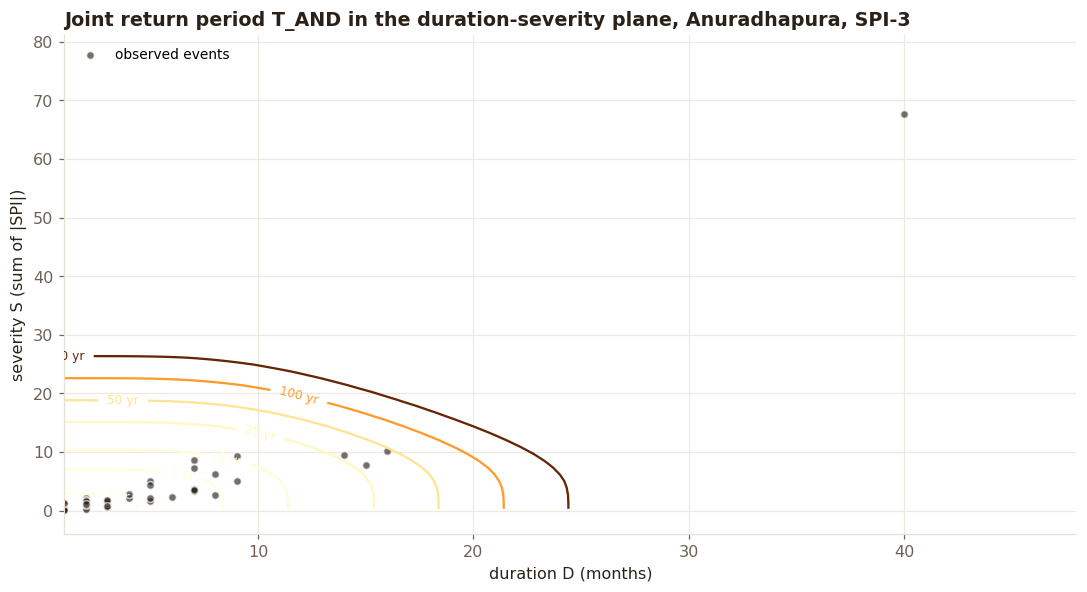

<span style='color:#6E6255'>*Each curve joins droughts that are equally rare; events beyond the 50-year curve are exceptional.*</span>

,Return period (years),Drought length (months),Drought severity score,"T_AND(d,s) years","T_OR(d,s) years"
0,2,4.4,2.92,2.3,1.8
1,5,8.4,7.03,7.2,3.8
2,10,11.4,10.44,19.4,6.7
3,20,14.4,14.00,58.7,12.1
4,50,18.4,18.85,294.8,27.3
5,100,21.4,22.59,1081.2,52.4


,duration at least (months),severity at least,T_AND (years),T_OR (years)
0,3,3,2.1,1.4
1,6,6,4.5,2.7
2,6,10,9.7,2.8
3,12,12,27.4,8.0
4,12,20,109.0,10.6


In [30]:
dg = np.linspace(1, max(events["Duration"].max() * 1.2, 12), 70)
sg = np.linspace(0.3, max(events["Severity"].max() * 1.2, 8), 70)
TA = np.array([[T_and(model, d, s) for d in dg] for s in sg])
fig, ax = plt.subplots(figsize=(10, 5.5))
cs = ax.contour(dg, sg, TA, levels=[2, 5, 10, 25, 50, 100, 200], cmap="YlOrBr", linewidths=1.5)
ax.clabel(cs, fmt="%d yr", fontsize=8)
ax.scatter(events["Duration"], events["Severity"], s=26, color=theme.INK, alpha=0.65, edgecolor="white", label="observed events")
ax.set_title(f"Joint return period T_AND in the duration-severity plane, {DISTRICT}, SPI-{SCALE}")
ax.set_xlabel("duration D (months)"); ax.set_ylabel("severity S (sum of |SPI|)"); ax.legend(loc="upper left")
plt.tight_layout(); plt.show()
nt.caption("Each curve joins droughts that are equally rare; events beyond the 50-year curve are exceptional.")

rp = return_period_table(model)
nt.show(rp)
chosen = pd.DataFrame([{"duration at least (months)": d, "severity at least": s,
                        "T_AND (years)": T_and(model, d, s), "T_OR (years)": T_or(model, d, s)}
                       for d, s in [(3, 3), (6, 6), (6, 10), (12, 12), (12, 20)]])
nt.show(chosen, 1)

#### Interpretation

In [31]:
r66 = chosen.iloc[1]
nt.interpret(f"""
In {DISTRICT}, a drought lasting **at least 6 months and with severity at least 6** happens on average once every
**{r66['T_AND (years)']:.1f} years** (T_AND), while one that reaches either threshold happens every
{r66['T_OR (years)']:.1f} years (T_OR). The design table shows that a "10-year" drought by length alone is a
{rp.loc[rp['Return period (years)'] == 10, 'Drought length (months)'].iloc[0]:.1f}-month drought, and having both its
length and its severity together is rarer ({rp.loc[rp['Return period (years)'] == 10, 'T_AND(d,s) years'].iloc[0]:.1f} years).
How to read it: use T_AND to plan for damaging droughts (long and deep), T_OR for how often some warning will be
needed. Values beyond about 40 years go past the 42-year record and are extrapolations.
""")


In Anuradhapura, a drought lasting **at least 6 months and with severity at least 6** happens on average once every
**4.5 years** (T_AND), while one that reaches either threshold happens every
2.7 years (T_OR). The design table shows that a "10-year" drought by length alone is a
11.4-month drought, and having both its
length and its severity together is rarer (19.4 years).
How to read it: use T_AND to plan for damaging droughts (long and deep), T_OR for how often some warning will be
needed. Values beyond about 40 years go past the 42-year record and are extrapolations.


## 12. All 25 districts

The same steps for every district at the same time window, to see how drought behaviour changes across the island.

In [32]:
rows = []
for d in common.list_districts():
    m_d, _, ev_d = build_district_model(common.read_rainfall(d), d, SCALE)
    rows.append({"district": d, "events": m_d.n_events, "mean duration (months)": m_d.marginals.mean_D,
                 "mean severity": m_d.marginals.mean_S, "longest (months)": int(ev_d["Duration"].max()),
                 "Kendall tau": m_d.kendall_tau, "copula": m_d.best_family, "theta": m_d.best_theta,
                 "T_AND 6 mo and S 6 (years)": T_and(m_d, 6, 6)})
allsum = pd.DataFrame(rows)
nt.show(allsum, 2)

,district,events,mean duration (months),mean severity,longest (months),Kendall tau,copula,theta,T_AND 6 mo and S 6 (years)
0,Ampara,50,5.34,3.96,37,0.80,Frank,16.04,3.99
1,Anuradhapura,58,4.34,3.35,40,0.76,Frank,14.06,4.54
2,Badulla,37,7.19,5.38,41,0.83,Frank,17.68,3.87
3,Batticaloa,57,4.51,3.45,38,0.80,Frank,15.97,4.30
4,Colombo,49,5.16,4.11,41,0.81,Gumbel,4.32,4.05
5,Galle,38,6.79,5.40,44,0.83,Frank,17.94,4.05
6,Gampaha,49,5.16,4.11,41,0.81,Gumbel,4.32,4.05
7,Hambantota,38,6.74,5.23,41,0.84,Frank,19.06,4.02
8,Jaffna,59,4.32,3.41,19,0.76,Gumbel,3.38,4.31
9,Kalutara,39,6.56,5.29,42,0.85,Gumbel,4.75,4.01


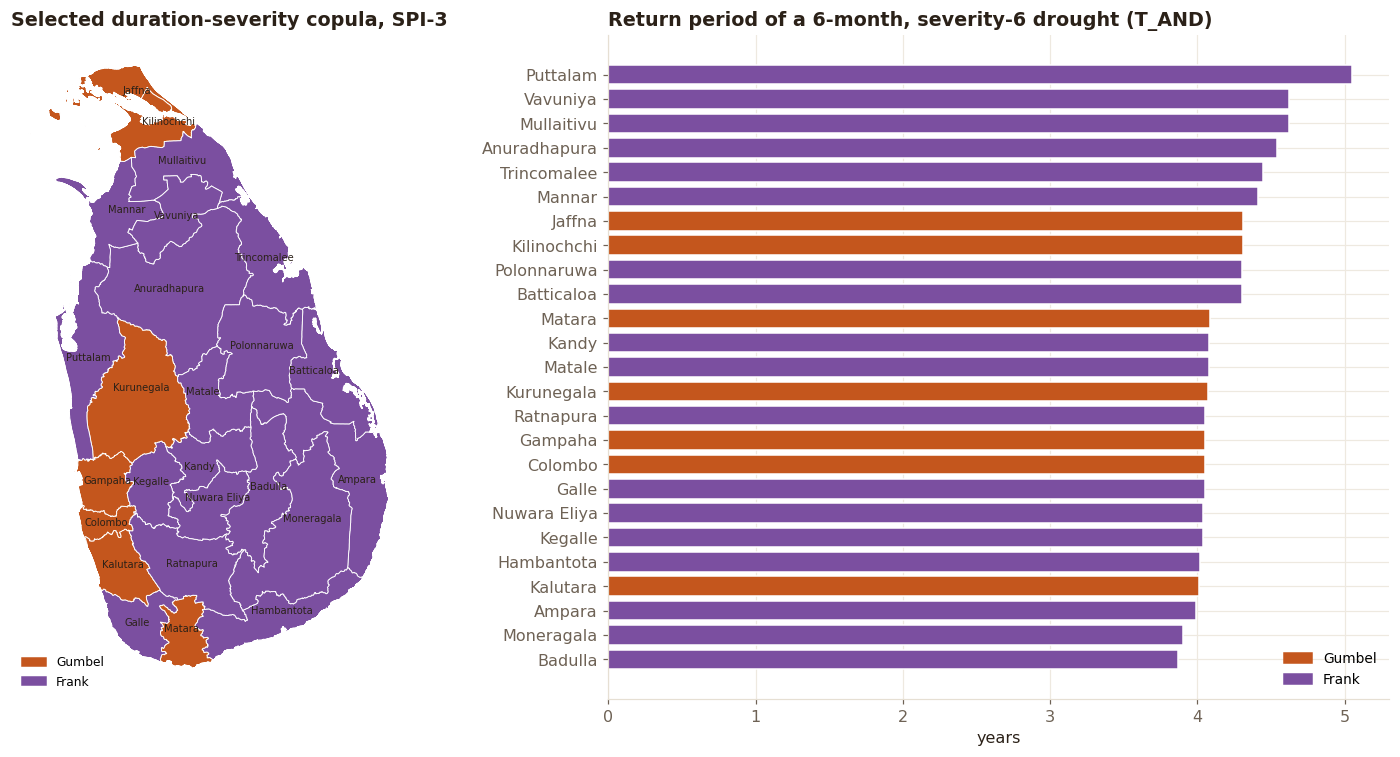

<span style='color:#6E6255'>*Colour shows the copula chosen by AIC; shorter bars mean such droughts come back more often.*</span>

In [33]:
fig, ax = plt.subplots(1, 2, figsize=(14, 7), gridspec_kw={"width_ratios": [1, 1.2]})
fam_colours = {"Gumbel": theme.CLASS_COLOURS["Severely dry"], "Clayton": theme.CLASS_COLOURS["Very wet"],
               "Frank": theme.INDEX_COLOURS["MSDI"]}
nt.district_map(ax[0], allsum.set_index("district")["copula"], f"Selected duration-severity copula, SPI-{SCALE}",
                categorical=True, colours=fam_colours)
srt = allsum.sort_values("T_AND 6 mo and S 6 (years)")
ax[1].barh(srt["district"], srt["T_AND 6 mo and S 6 (years)"], color=[fam_colours[c] for c in srt["copula"]], edgecolor="white")
ax[1].set_title("Return period of a 6-month, severity-6 drought (T_AND)"); ax[1].set_xlabel("years")
ax[1].legend(handles=[nt.Patch(color=c, label=k) for k, c in fam_colours.items() if k in set(srt["copula"])],
             loc="lower right")
plt.tight_layout(); plt.show()
nt.caption("Colour shows the copula chosen by AIC; shorter bars mean such droughts come back more often.")

#### Interpretation

In [34]:
fam = allsum["copula"].value_counts()
fast = allsum.nsmallest(3, "T_AND 6 mo and S 6 (years)")
nt.interpret(f"""
The selected copula is {', '.join(f'**{k}** in {v} districts' for k, v in fam.items())}. Kendall's tau ranges from
{allsum['Kendall tau'].min():.2f} to {allsum['Kendall tau'].max():.2f}, so duration and severity are strongly linked
everywhere. A 6-month drought with severity at least 6 returns most often in
{', '.join(f"{r['district']} ({r['T_AND 6 mo and S 6 (years)']:.1f} yr)" for _, r in fast.iterrows())}.
{DISTRICT} has {int(allsum.loc[allsum['district'] == DISTRICT, 'events'].iloc[0])} events. Six pairs of districts share
one NASA grid cell (for example Colombo and Gampaha), so their rows are identical.
""")


The selected copula is **Frank** in 18 districts, **Gumbel** in 7 districts. Kendall's tau ranges from
0.75 to 0.85, so duration and severity are strongly linked
everywhere. A 6-month drought with severity at least 6 returns most often in
Badulla (3.9 yr), Moneragala (3.9 yr), Ampara (4.0 yr).
Anuradhapura has 58 events. Six pairs of districts share
one NASA grid cell (for example Colombo and Gampaha), so their rows are identical.


## 13. SPI on the shared test droughts

SPI-3 is scored on the same test droughts and by the same rule as MSDI and SSI (`threshold_skill.py`). Only impact, situation
report, DMC report and news impact rows are used, never the SPI-study rows, because testing SPI on SPI studies is circular. A year
is flagged with at least 3 months at or below -1. Notebook 03 shows the side-by-side comparison.

$$\text{HR}=\frac{\text{test droughts with a flagged year}}{\text{test droughts}},\qquad
\text{FAR}=\frac{\text{flagged years with no drought evidence}}{\text{years with no drought evidence}},\qquad \text{skill}=\text{HR}-\text{FAR}$$

In [35]:
import threshold_skill as TS
shared = TS.compute()
spi_prov = shared.by_province[shared.by_province["index"] == "SPI-3"]
keep = ["province", "separate droughts", "hit rate", "false alarm rate", "skill", "warning"]
nt.show(spi_prov[keep].rename(columns={"separate droughts": "test droughts"}).dropna(subset=["skill"]).sort_values("test droughts", ascending=False), 2)
here = shared.by_district[(shared.by_district["index"] == "SPI-3") & (shared.by_district["district"] == DISTRICT)].iloc[0]

,province,test droughts,hit rate,false alarm rate,skill,warning
10,North Central,8,0.38,0.08,0.30,
52,North Western,5,0.33,0.16,0.17,
16,Uva,4,0.00,0.26,-0.26,"very few test droughts, treat as indicative only"
28,Southern,4,0.20,0.32,-0.12,"very few test droughts, treat as indicative only"
4,Eastern,3,0.50,0.21,0.29,"very few test droughts, treat as indicative only"
34,Northern,3,0.44,0.21,0.24,"very few test droughts, treat as indicative only"
40,Central,1,0.00,0.19,-0.19,"very few test droughts, treat as indicative only"


#### Interpretation

In [36]:
nat = shared.national.set_index("index").loc["SPI-3"]
tested = spi_prov.dropna(subset=["skill"]).sort_values("separate droughts", ascending=False)
nt.interpret(f"""
Over all tested districts, on {int(nat['separate droughts'])} test droughts, SPI-3 finds **{nat['hit rate']:.2f}** of them with a false alarm rate of **{nat['false alarm rate']:.2f}**, a skill of **{nat['skill']:+.2f}**. By province it runs from {tested['skill'].min():+.2f} to {tested['skill'].max():+.2f}, and
{len(tested)} of 9 provinces can be scored. {DISTRICT + ' has ' + str(int(here['droughts'])) + ' test droughts, with a skill of ' + format(here['skill'], '+.2f') + '.' if here['droughts'] else DISTRICT + ' has no test droughts, so it has no score.'} Provinces marked "{TS.FEW_WARNING}" move a lot on one drought. See notebook 03 for SPI, SSI and MSDI side by side.
""")


Over all tested districts, on 11 test droughts, SPI-3 finds **0.32** of them with a false alarm rate of **0.21**, a skill of **+0.11**. By province it runs from -0.26 to +0.30, and
7 of 9 provinces can be scored. Anuradhapura has 8 test droughts, with a skill of +0.30. Provinces marked "very few test droughts, treat as indicative only" move a lot on one drought. See notebook 03 for SPI, SSI and MSDI side by side.


## 14. Summary of findings

In [37]:
nt.interpret(f"""
1. {DISTRICT} receives about {annual.mean():.0f} mm a year with a strong seasonal cycle, so SPI is computed per calendar month.
2. Gamma fits the {SCALE}-month totals well in every calendar month (mean AIC gap to the best family {gap.mean():.1f}) and is kept as the McKee standard.
3. SPI-{SCALE} has mean {z.mean():+.2f} and SD {z.std():.2f}; {100 * dry / counts.sum():.1f}% of months are moderately dry or worse.
4. The driest {SCALE}-month period ended in {calendar.month_name[EX_MONTH]} {int(ex['Year'])} with SPI {ex[col]:.2f}.
5. Run theory gives {model.n_events} drought events, the worst lasting {int(w['Duration'])} months ({start:%b %Y} to {end:%b %Y}).
6. Duration and severity are strongly dependent (Kendall tau {model.kendall_tau:.2f}); the {model.best_family} copula has the lowest AIC.
7. A drought of at least 6 months and severity 6 returns about every {r66['T_AND (years)']:.1f} years (T_AND).
8. Across the island the {fam.idxmax()} copula is selected most often ({fam.max()} of 25 districts).
""")


1. Anuradhapura receives about 1328 mm a year with a strong seasonal cycle, so SPI is computed per calendar month.
2. Gamma fits the 3-month totals well in every calendar month (mean AIC gap to the best family 0.8) and is kept as the McKee standard.
3. SPI-3 has mean +0.00 and SD 1.00; 14.1% of months are moderately dry or worse.
4. The driest 3-month period ended in November 1995 with SPI -3.02.
5. Run theory gives 58 drought events, the worst lasting 40 months (May 1994 to Aug 1997).
6. Duration and severity are strongly dependent (Kendall tau 0.76); the Frank copula has the lowest AIC.
7. A drought of at least 6 months and severity 6 returns about every 4.5 years (T_AND).
8. Across the island the Frank copula is selected most often (18 of 25 districts).


## 15. Limitations

- **Satellite model data.** NASA POWER rainfall is a gridded estimate (cells about 50 km wide), not gauge data;
  six pairs of small districts share one grid cell and have identical results.
- **Record length.** 42 years give about 42 values per calendar month for the Gamma fits and a few dozen drought
  events for the copula, so return periods beyond about 40 years are extrapolations.
- **Fixed family choices.** Gamma (SPI), Exponential (duration) and Gamma (severity) are kept for comparability
  even where another family has a slightly lower AIC.
- **Class cut-offs.** The McKee classes (-1, -1.5, -2) are not calibrated against crop losses in each district.
- **Zero months.** The code replaces zero totals with 0.001 mm instead of using the mixed distribution; with
  district averages this rarely matters.
- **Run theory threshold 0** counts mild dry spells as events; a lower threshold would give fewer, deeper events.